# Pan-cancer pooled ROC (pretrained three-head model)

Counterpart of `CODEX_hcc/Pred_statistic_visual_hcc_all.ipynb` **Pooled StarDist ROC**, but labels are the pan-cancer L1 / L12 / L2 ontology.

1. Run `PanCancer_predict_visualize.py` (writes per-section AUROC CSVs under `data/PanCancer/pred_all_spatial/stardist_roc/`).
2. This notebook concatenates those CSVs and plots pooled OvR ROC for L2 / L12 / L1.
3. If macro AUROC is strong, the same `best_mlp_gpu.pt` can be applied to hold-out cancers (e.g. Prostate) **after** UNI matched h5ads exist.

```bash
conda activate SeededNTM
python -u code/PanCancer/PanCancer_predict_visualize.py --datasets BRCA --max-sections 1
python -u code/PanCancer/PanCancer_predict_visualize.py --include-incomplete-lung
```


In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import pandas as pd

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
PKG = REPO / "code" / "Hist2Pheno_pkg"
PAN = REPO / "code" / "PanCancer"
for p in (PKG, PAN):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from uni_label_cv_helpers import plot_pooled_stardist_tier_rocs

PRED = REPO / "data" / "PanCancer" / "pred_all_spatial"
ROC_ROOT = PRED / "stardist_roc"
OUT = PRED / "pooled_roc"
OUT.mkdir(parents=True, exist_ok=True)
print("ROC_ROOT", ROC_ROOT, "exists", ROC_ROOT.is_dir())
print("n sample dirs", len(list(ROC_ROOT.glob("*"))) if ROC_ROOT.is_dir() else 0)

met = PRED / "metrics_per_section.csv"
if met.is_file():
    df = pd.read_csv(met)
    print(df.groupby("dataset")[["macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells"]].mean())
    display(df.head())

ROC_ROOT /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/stardist_roc exists True
n sample dirs 896
                macro_auc_L1_cells  macro_auc_L12_cells  macro_auc_L2_cells
dataset                                                                    
BRCA                      0.875284             0.840700            0.809428
CRC                       0.658583             0.645969            0.622325
GBM                       0.606918             0.618884            0.614994
GIST                      0.665194             0.646584            0.641447
HCC                       0.791508             0.775549            0.749878
Lung                      0.686929             0.694819            0.670554
LungIncomplete                 NaN                  NaN                 NaN
PDAC                      0.772738             0.765371            0.719977


,section_id,dataset,sample,n_matched,n_stardist_all,macro_auc_L1,macro_auc_L12,macro_auc_L2,panel,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells
0,PDAC::Charvill-94_c001_v001_r001_reg088,PDAC,Charvill-94_c001_v001_r001_reg088,3746,6828,0.804742,0.784096,0.697654,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.804742,0.784096,0.697654
1,PDAC::Charvill-94_c001_v001_r001_reg112,PDAC,Charvill-94_c001_v001_r001_reg112,7098,10375,0.799918,0.828415,0.759202,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.799918,0.828415,0.759202
2,PDAC::Charvill-94_c001_v001_r001_reg132,PDAC,Charvill-94_c001_v001_r001_reg132,4452,7389,0.723345,0.727149,0.692886,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.723345,0.727149,0.692886
3,PDAC::Charvill-94_c001_v001_r001_reg138,PDAC,Charvill-94_c001_v001_r001_reg138,4328,6622,0.646962,0.640809,0.629653,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.646962,0.640809,0.629653
4,PDAC::Charvill-94_c001_v001_r001_reg143,PDAC,Charvill-94_c001_v001_r001_reg143,1112,11827,0.646657,0.688246,0.665078,/nobackup2/users/lingyu/Python/Hist2Pheno/data...,0.646657,0.688246,0.665078


## Pooled ROC (matched UNI cells, pan-cancer L1 / L12 / L2)

Uses the same CSV layout as cohort StarDist AUROC tables so `plot_pooled_stardist_tier_rocs` can concatenate all sections.



=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
  CRC__P1CRC: 149,492 cells, 20 local classes
  CRC__P2CRC: 202,900 cells, 20 local classes
  CRC__P5CRC: 116,121 cells, 20 local classes
  GBM__P174511_Initial: 35,961 cells, 20 local classes
  GBM__P179161_Recurrent: 135,055 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 20 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 20 local classe

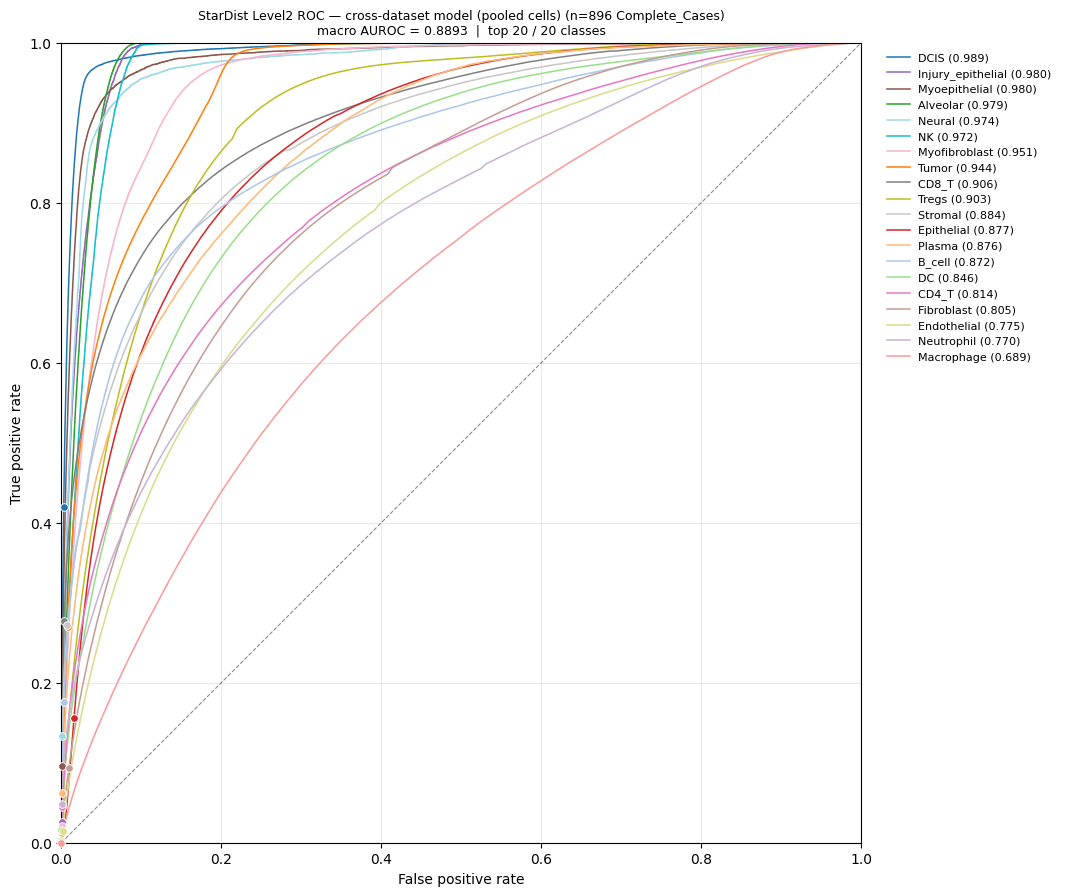

Pooled macro AUROC (L2): 0.8893


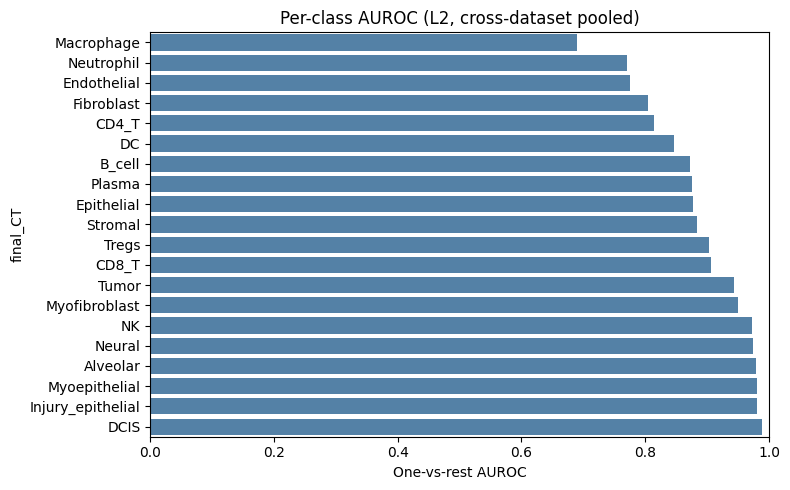


=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
  CRC__P1CRC: 149,492 cells, 8 local classes
  CRC__P2CRC: 202,900 cells, 8 local classes
  CRC__P5CRC: 116,121 cells, 8 local classes
  GBM__P174511_Initial: 35,961 cells, 8 local classes
  GBM__P179161_Recurrent: 135,055 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 8 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 8 local classes
  GI

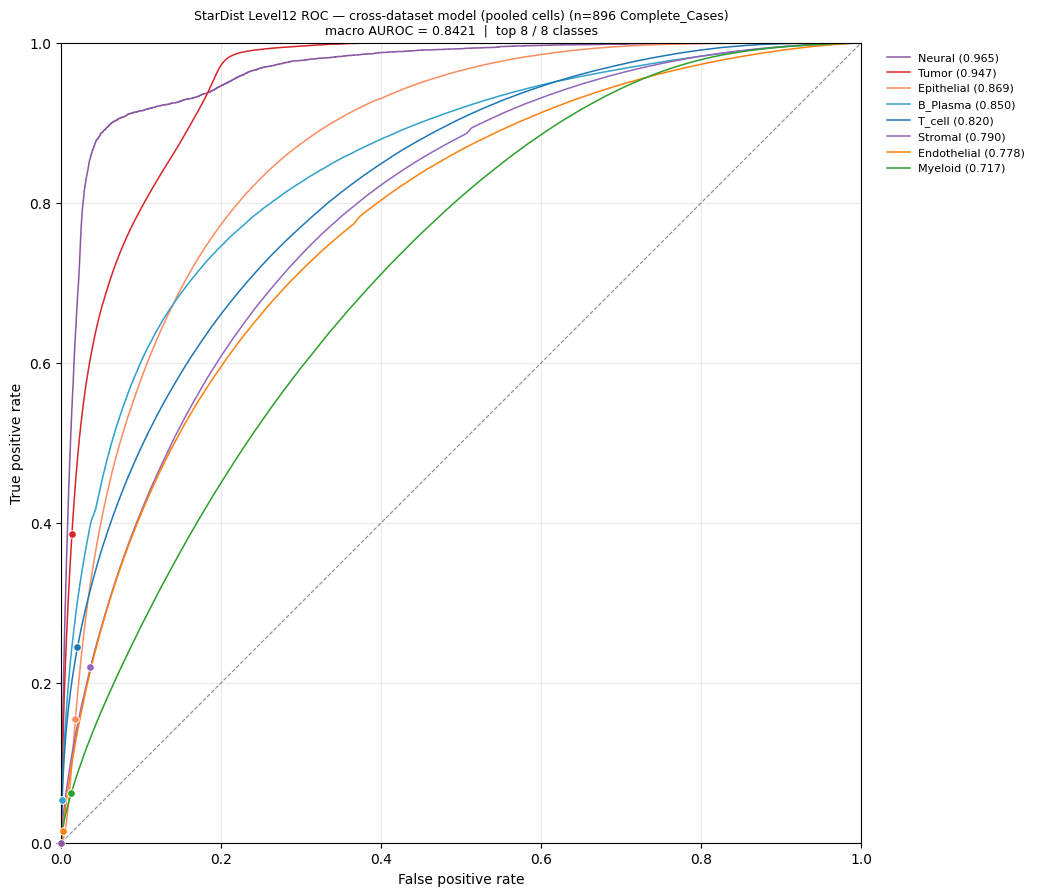

Pooled macro AUROC (L12): 0.8421


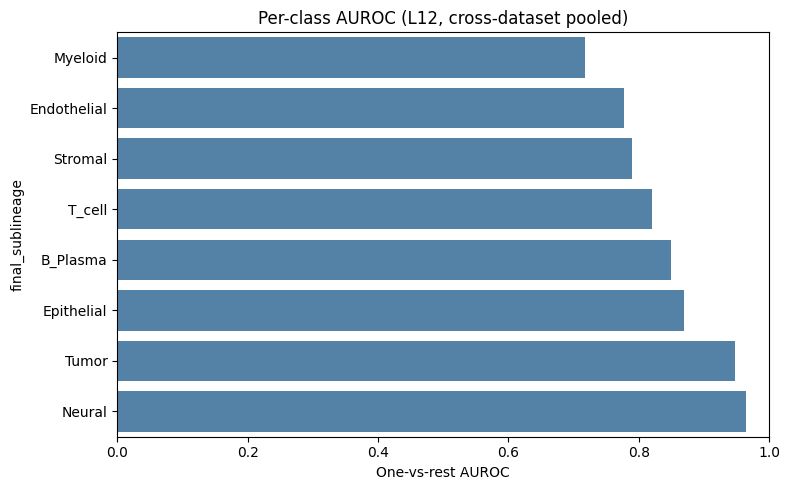


=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
  CRC__P1CRC: 149,492 cells, 5 local classes
  CRC__P2CRC: 202,900 cells, 5 local classes
  CRC__P5CRC: 116,121 cells, 5 local classes
  GBM__P174511_Initial: 35,961 cells, 5 local classes
  GBM__P179161_Recurrent: 135,055 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg001: 5,257 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg002: 3,098 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg003: 8,740 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg004: 12,062 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg005: 4,090 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg006: 5,225 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg007: 10,544 cells, 5 local classes
  GIST__Charvill-94_c009_v001_r001_reg008: 6,964 cells, 5 local classes
  GIST

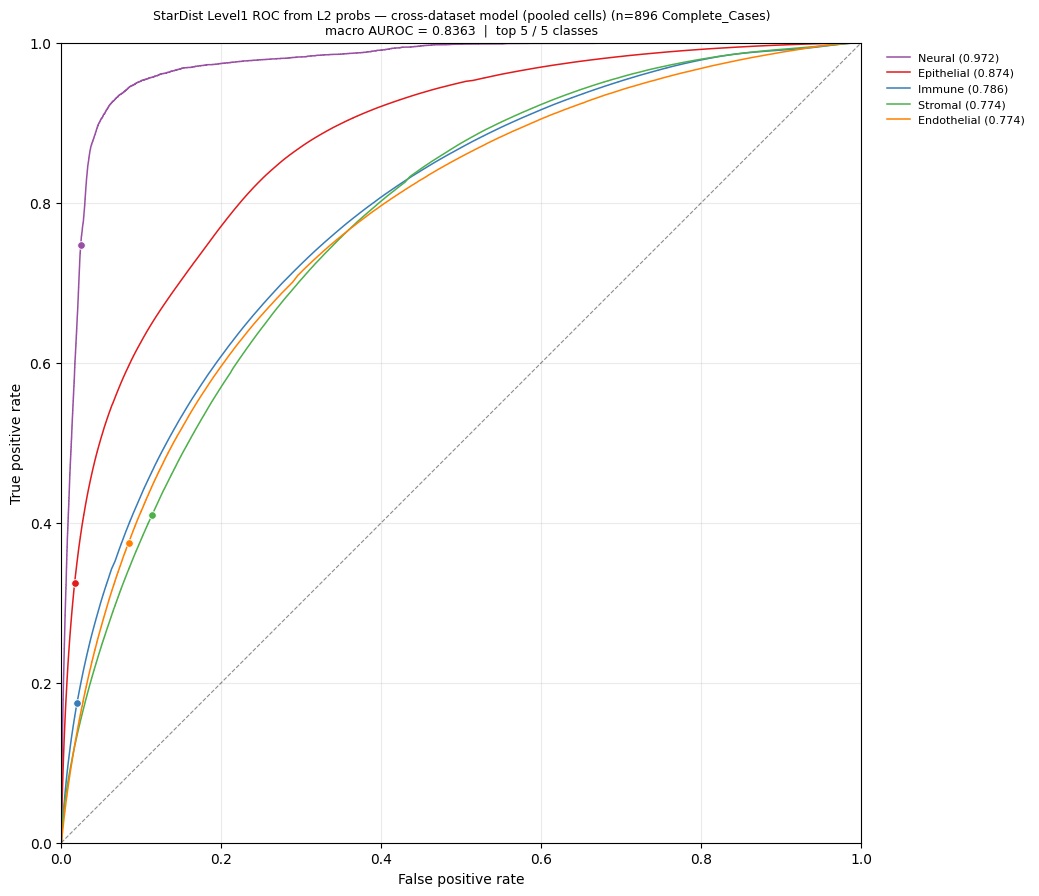

Pooled macro AUROC (L1): 0.8363


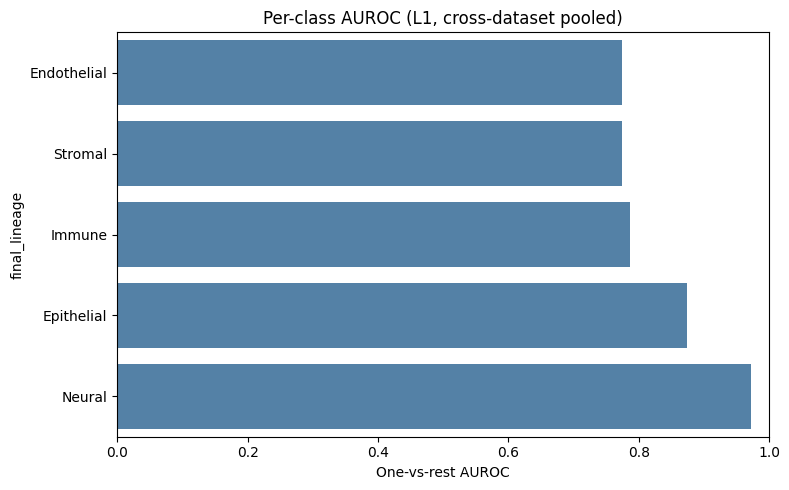

pooled L2 macro AUROC = 0.8893
pooled L12 macro AUROC = 0.8421
pooled L1 macro AUROC = 0.8363


In [2]:
if not ROC_ROOT.is_dir() or not any(ROC_ROOT.iterdir()):
    raise FileNotFoundError(
        f"No per-section AUROC CSVs under {ROC_ROOT}. "
        "Run code/PanCancer/PanCancer_predict_visualize.py first."
    )

results = plot_pooled_stardist_tier_rocs(
    ROC_ROOT,
    OUT,
    tiers=("l2", "l12", "l1"),
    layout="pooled_stardist",
    pan_organ="pancancer",
    figsize=(8.0, 8.0),
    show_barplot=True,
    save_per_class_csv=True,
    show=True,
)
for tier, rec in results.items():
    info = rec.get("roc_info") or {}
    print(f"pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")

## Hold-out cancers (Prostate and others under `data/`)

Pretrained weights: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

| Folder | Status |
|--------|--------|
| `data/ST/Prostate` | HE + StarDist; **no** `{sample}_matched_features.h5ad` yet |
| `data/Visium/Prostate` | Visium counts; needs HE alignment + UNI + h5ad |

Apply the pan-cancer model only after a matched UNI h5ad exists, then:

```bash
python -u code/PanCancer/PanCancer_predict_visualize.py \
  --index-csv /path/to/prostate_section_index.csv
```

Native labels (if any) should map through `celltype_pancancer` aliases, or leave GT empty and only inspect StarDist-all spatial maps.
